## Algorithms have been taken as of 
https://www.researchgate.net/profile/Jagbir-Kaur-5/publication/386461380_Anomaly_Detection_in_Cybersecurity_Leveraging_Machine_Learning_Algorithms/links/67520f87ba2f3a1eb8b05e79/Anomaly-Detection-in-Cybersecurity-Leveraging-Machine-Learning-Algorithms.pdf

## Isolation Forest

In [18]:
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc
import seaborn as sns
import matplotlib.pyplot as plt

In [10]:
df = pd.read_csv("encoded_dataset.csv")

In [12]:
df.head()

,network_packet_size,login_attempts,session_duration,ip_reputation_score,failed_logins,unusual_time_access,attack_detected,protocol_type_ICMP,protocol_type_TCP,protocol_type_UDP,protocol_type_nan,encryption_used_AES,encryption_used_DES,encryption_used_nan,browser_type_Chrome,browser_type_Edge,browser_type_Firefox,browser_type_Safari,browser_type_Unknown,browser_type_nan
0,0.496899,4,-0.381125,1.554930,1,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0
1,-0.143322,3,0.972960,-0.168029,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0
2,0.648132,3,-0.912503,2.301950,2,0,1,0,1,0,0,0,1,0,1,0,0,0,0,0
3,1.530327,4,-0.243473,-1.174443,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0
4,-0.239103,5,-0.330830,-1.560484,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0


In [14]:
# Define features and target(x)
features = ['login_attempts', 'failed_logins', 'unusual_time_access',
                'encryption_used_AES', 'encryption_used_DES', 'encryption_used_nan']
X = df[features]
y = df['attack_detected']

In [20]:
# Split the dataset into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [49]:
# Identify the percentage of the dataset labelled as anomaly.
print("Class distribution in the full dataset:")
print(df['attack_detected'].value_counts(normalize=True))

Class distribution in the full dataset:
attack_detected
0    0.552899
1    0.447101
Name: proportion, dtype: float64


In [51]:
# Train isolation forest
ratio_anomaly = df['attack_detected'].value_counts(normalize=True)[1]
Isolation_Forest = IsolationForest(random_state=42, contamination = ratio_anomaly)
Isolation_Forest.fit(X_train)

IsolationForest(contamination=0.44710076543986577, random_state=42)

In [53]:
# Predict Anomalies 
Trained_predict = Isolation_Forest.predict(X_test)

In [55]:
# Convert the -1 and 1 labels to 0 (normal) and 1 (attack)
Trained_predict = [1 if x == -1 else 0 for x in Trained_predict]

# This is done becasue isolation forest labels anomalies as -1 and 1 for normal. 
# Since, in our target column, 1 is for anomaly and 0 is for normal data, we perform this conversion.

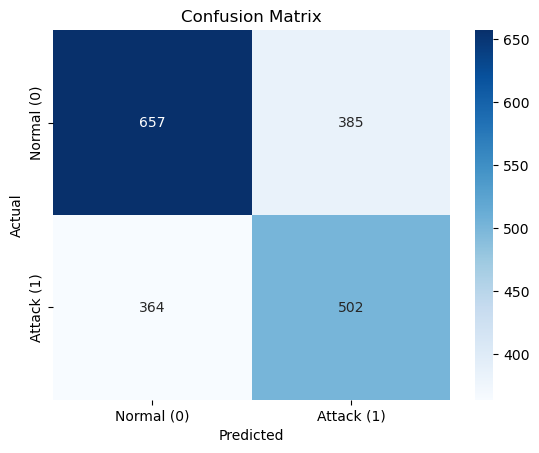

In [57]:
# PLot a confusion matrix

conf_Matrix = confusion_matrix(y_test, Trained_predict)
sns.heatmap(conf_Matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal (0)", "Attack (1)"],
            yticklabels=["Normal (0)", "Attack (1)"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [59]:
# Classification report
report = classification_report(y_test, Trained_predict, target_names=["Normal", "Attack"])
print("Classification Report:\n", report)

Classification Report:
               precision    recall  f1-score   support

      Normal       0.64      0.63      0.64      1042
      Attack       0.57      0.58      0.57       866

    accuracy                           0.61      1908
   macro avg       0.60      0.61      0.60      1908
weighted avg       0.61      0.61      0.61      1908



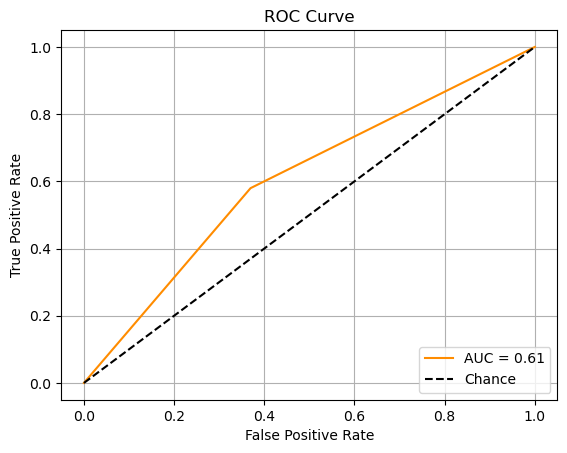

In [61]:
# PLot an roc curve
fpr, tpr, _ = roc_curve(y_test, Trained_predict)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}", color="darkorange")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()